# Iris Flower Classification

## 1. Import Libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

## 2. Load Dataset

In [2]:
data_path = Path("../data/Iris.csv")

df = pd.read_csv(data_path)

df.head()

,Id,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Species
0,1,5.1,3.5,1.4,0.2,Iris-setosa
1,2,4.9,3.0,1.4,0.2,Iris-setosa
2,3,4.7,3.2,1.3,0.2,Iris-setosa
3,4,4.6,3.1,1.5,0.2,Iris-setosa
4,5,5.0,3.6,1.4,0.2,Iris-setosa


## 3. Understand the Dataset

In [3]:
print("Dataset shape:", df.shape)

print("\nDataset information:")
df.info()

print("\nDescriptive statistics:")
display(df.describe())

print("\nMissing values:")
print(df.isnull().sum())

print("\nSpecies distribution:")
print(df["Species"].value_counts())

print("\nUnique species:")
print(df["Species"].unique())

Dataset shape: (150, 6)

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 6 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             150 non-null    int64  
 1   SepalLengthCm  150 non-null    float64
 2   SepalWidthCm   150 non-null    float64
 3   PetalLengthCm  150 non-null    float64
 4   PetalWidthCm   150 non-null    float64
 5   Species        150 non-null    str    
dtypes: float64(4), int64(1), str(1)
memory usage: 7.2 KB

Descriptive statistics:


,Id,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm
count,150.000000,150.000000,150.000000,150.000000,150.000000
mean,75.500000,5.843333,3.054000,3.758667,1.198667
std,43.445368,0.828066,0.433594,1.764420,0.763161
min,1.000000,4.300000,2.000000,1.000000,0.100000
25%,38.250000,5.100000,2.800000,1.600000,0.300000
50%,75.500000,5.800000,3.000000,4.350000,1.300000
75%,112.750000,6.400000,3.300000,5.100000,1.800000
max,150.000000,7.900000,4.400000,6.900000,2.500000



Missing values:
Id               0
SepalLengthCm    0
SepalWidthCm     0
PetalLengthCm    0
PetalWidthCm     0
Species          0
dtype: int64

Species distribution:
Species
Iris-setosa        50
Iris-versicolor    50
Iris-virginica     50
Name: count, dtype: int64

Unique species:
<StringArray>
['Iris-setosa', 'Iris-versicolor', 'Iris-virginica']
Length: 3, dtype: str


## 4. Exploratory Data Analysis (EDA)

Exploratory Data Analysis is used to understand the distribution and relationships
within the dataset before training machine-learning models.

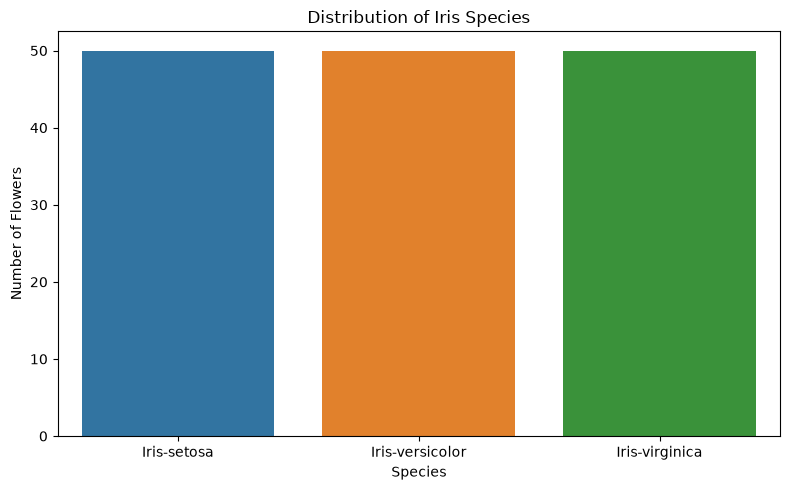

In [4]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="Species",
    hue="Species",
    legend=False
)

plt.title("Distribution of Iris Species")
plt.xlabel("Species")
plt.ylabel("Number of Flowers")

plt.tight_layout()
plt.show()

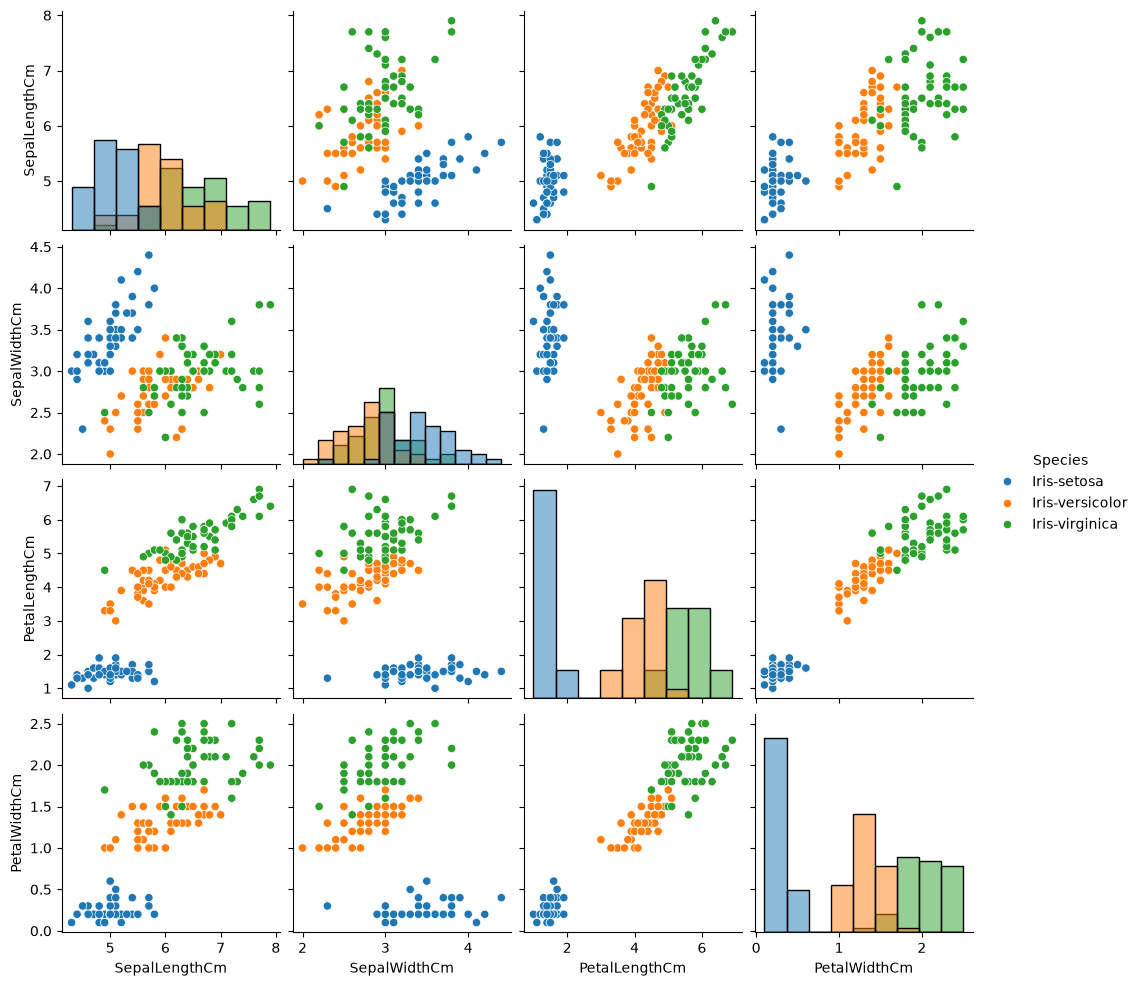

In [5]:
sns.pairplot(
    df.drop(columns=["Id"]),
    hue="Species",
    diag_kind="hist"
)

plt.show()

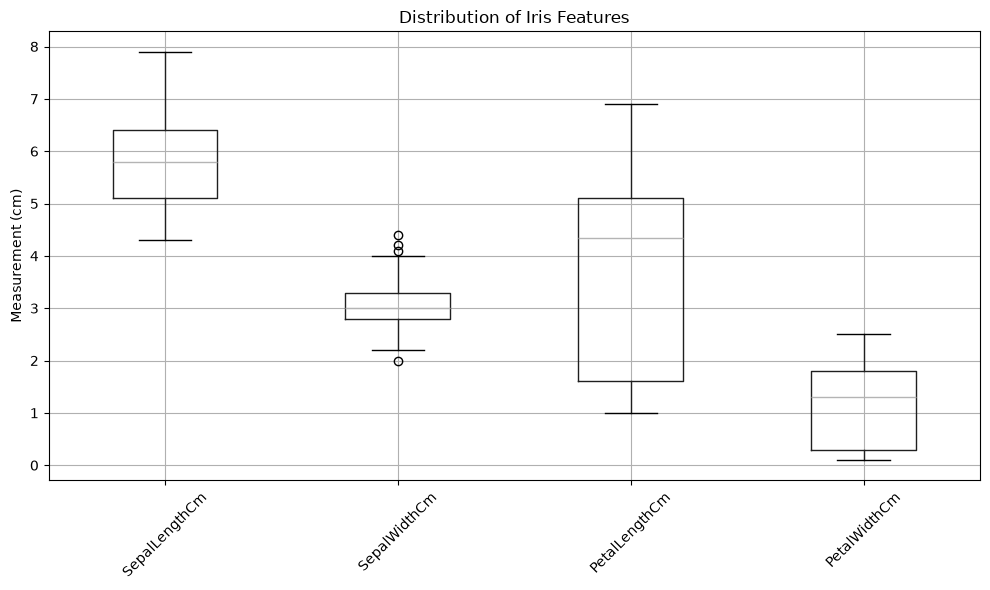

In [6]:
plt.figure(figsize=(10, 6))

df.drop(columns=["Id", "Species"]).boxplot()

plt.title("Distribution of Iris Features")
plt.ylabel("Measurement (cm)")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

## 5. Prepare the Features and Target

The four flower measurements are used as input features.

The Id column is removed because it is only an identifier and does not provide
useful information for predicting the flower species.

The Species column is used as the target variable.

In [7]:
X = df[
    [
        "SepalLengthCm",
        "SepalWidthCm",
        "PetalLengthCm",
        "PetalWidthCm"
    ]
]

y = df["Species"]

print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (150, 4)
Target shape: (150,)


## 6. Split the Data into Training and Testing Sets

The dataset is divided into:

- 80% for training the machine-learning models
- 20% for testing their performance

`stratify=y` keeps the proportion of each Iris species similar in both sets.

In [8]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

Training samples: 120
Testing samples: 30


## 7. Feature Scaling

StandardScaler standardizes the numerical features so that they have a
similar scale.

The scaler is fitted only on the training data and then applied to both
training and testing data. This prevents data leakage.

In [9]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Training data scaled:", X_train_scaled.shape)
print("Testing data scaled:", X_test_scaled.shape)

Training data scaled: (120, 4)
Testing data scaled: (30, 4)


## 8. Train and Compare Machine-Learning Models

Several classification algorithms are trained using the same training data.
Their performance will be compared using accuracy, precision, recall, and F1-score.

In [10]:
models = {
    "Logistic Regression": LogisticRegression(max_iter=200, random_state=42),
    "K-Nearest Neighbors": KNeighborsClassifier(n_neighbors=5),
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "Support Vector Machine": SVC(random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=100, random_state=42)
}

results = []

for name, model in models.items():
    model.fit(X_train_scaled, y_train)
    y_pred = model.predict(X_test_scaled)

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, average="weighted"),
        "Recall": recall_score(y_test, y_pred, average="weighted"),
        "F1 Score": f1_score(y_test, y_pred, average="weighted")
    })

results_df = pd.DataFrame(results)

results_df

,Model,Accuracy,Precision,Recall,F1 Score
0,Logistic Regression,0.933333,0.933333,0.933333,0.933333
1,K-Nearest Neighbors,0.933333,0.944444,0.933333,0.932660
2,Decision Tree,0.900000,0.902357,0.900000,0.899749
3,Support Vector Machine,0.966667,0.969697,0.966667,0.966583
4,Random Forest,0.900000,0.902357,0.900000,0.899749


## 9. Detailed Evaluation of the Support Vector Machine

The Support Vector Machine achieved the highest observed performance on the
test set. A confusion matrix and classification report are used to examine
its predictions in more detail.

In [11]:
svm_model = models["Support Vector Machine"]

y_pred_svm = svm_model.predict(X_test_scaled)

print("Classification Report:")
print(classification_report(y_test, y_pred_svm))

Classification Report:
                 precision    recall  f1-score   support

    Iris-setosa       1.00      1.00      1.00        10
Iris-versicolor       1.00      0.90      0.95        10
 Iris-virginica       0.91      1.00      0.95        10

       accuracy                           0.97        30
      macro avg       0.97      0.97      0.97        30
   weighted avg       0.97      0.97      0.97        30



## 10. Confusion Matrix

The confusion matrix shows the number of correct and incorrect predictions
for each Iris species.

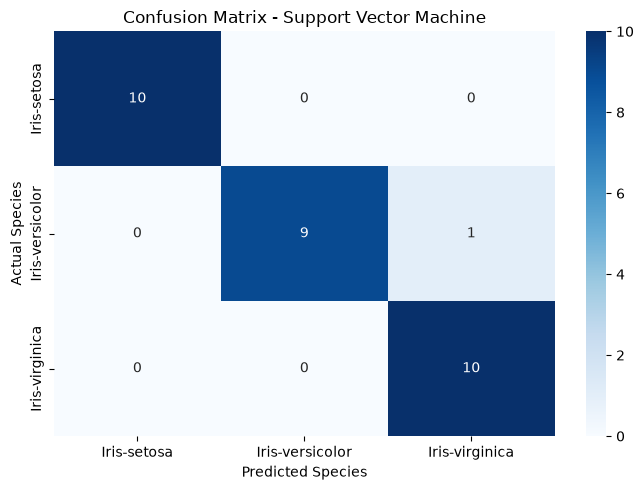

In [12]:
cm = confusion_matrix(y_test, y_pred_svm)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=svm_model.classes_,
    yticklabels=svm_model.classes_
)

plt.title("Confusion Matrix - Support Vector Machine")
plt.xlabel("Predicted Species")
plt.ylabel("Actual Species")

plt.tight_layout()
plt.show()

## 11. Predict the Species of a New Flower

The trained SVM model is used to predict the species of a new flower
based on its sepal and petal measurements.

In [13]:
new_flower = pd.DataFrame(
    [[5.1, 3.5, 1.4, 0.2]],
    columns=[
        "SepalLengthCm",
        "SepalWidthCm",
        "PetalLengthCm",
        "PetalWidthCm"
    ]
)

new_flower_scaled = scaler.transform(new_flower)

prediction = svm_model.predict(new_flower_scaled)

print("Predicted species:", prediction[0])

Predicted species: Iris-setosa


## 12. Conclusion

The Iris dataset was analyzed and used to train several machine-learning
classification models.

The Support Vector Machine achieved the highest observed performance on the
test set, with an accuracy of 96.67%.

The confusion matrix showed that 29 out of 30 test samples were correctly
classified.

The trained model was also tested with a new flower, which was predicted as
Iris-setosa.

In [14]:
results_df.to_csv("../results/model_comparison.csv", index=False)

print("Model comparison saved successfully.")

Model comparison saved successfully.
